# UrbanHub · Partie 1 : analyse météorologique (Développeur 1)

Ce notebook répond aux 4 questions métier de la partie 1 :

1. Peut-on identifier des **périodes météorologiques anormales** ?
2. Existe-t-il une **corrélation entre conditions météo et visibilité** ?
3. Quelle est l'**évolution saisonnière de la température** en France et dans les principales villes ?
4. Quels sont les **jours présentant des conditions météorologiques extrêmes** ?

**Données utilisées** (produites par `pipelines/batch_noaa/`) :

| Table | Contenu | Période |
|---|---|---|
| `clean/noaa/weather_hourly` | mesures de ~200 stations françaises (NOAA) | 01/2024 → 24/08/2025 |
| `curated/noaa/weather_city_hourly` | moyenne par ville (Paris, Lyon, Lille) et par heure : NOAA puis Open-Meteo | 01/2024 → aujourd'hui |

Les gros calculs sont faits par **Spark** sur le cluster ; seuls les petits résultats
(quelques milliers de lignes) sont ramenés dans **pandas** pour les graphiques.
Les graphiques sont enregistrés dans `docs/resultats/figures/`.

> Lancer : menu **Run → Run All Cells** (environ 3 à 6 minutes).

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.master(os.environ["SPARK_MASTER_URL"])
         .appName("analyse-meteo").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4.5)
CITY_COLORS = {"paris": "#1f77b4", "lyon": "#d62728", "lille": "#2ca02c"}
CITIES = list(CITY_COLORS)

FIG_DIR = "/app/docs/resultats/figures"
RES_DIR = "/app/docs/resultats"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=120, bbox_inches="tight")

clean = spark.read.parquet("s3a://clean/noaa/weather_hourly/")              # stations
curated = spark.read.parquet("s3a://curated/noaa/weather_city_hourly/")     # ville x heure
print(f"clean   : {clean.count():>10,} mesures, {clean.select('station_id').distinct().count()} stations")
print(f"curated : {curated.count():>10,} lignes ville x heure")
curated.groupBy("source").agg(F.min("timestamp").alias("debut"), F.max("timestamp").alias("fin"),
                              F.count("*").alias("lignes")).show()

clean   :  3,509,860 mesures, 208 stations


curated :     74,661 lignes ville x heure


+---------+-------------------+-------------------+------+
|   source|              debut|                fin|lignes|
+---------+-------------------+-------------------+------+
|     noaa|2024-01-01 00:00:00|2025-08-24 21:00:00| 42153|
|openmeteo|2025-08-25 00:00:00|2026-11-19 11:00:00| 32508|
+---------+-------------------+-------------------+------+



### Préparation : un tableau « une ligne par ville et par jour »

Spark regroupe les ~75 000 lignes horaires en ~3 000 lignes journalières :
température moyenne / min / max, vent maximum, cumul de pluie, pression moyenne.
On ne garde que les jours avec au moins 18 heures de mesures (jours assez complets).

In [14]:
daily = (curated
    .withColumn("date", F.to_date("timestamp"))
    .groupBy("city", "date")
    .agg(F.avg("temperature").alias("t_mean"),
         F.max("temperature").alias("t_max"),
         F.min("temperature").alias("t_min"),
         F.avg("wind_speed").alias("wind_mean"),
         F.max("wind_speed").alias("wind_max"),
         F.sum("precipitation").alias("precip"),
         F.avg("pressure").alias("pressure"),
         F.count("temperature").alias("n_hours"),
         F.first("source").alias("source"))
    .filter("n_hours >= 18")
    .toPandas())
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.sort_values(["city", "date"]).reset_index(drop=True)
daily["month"] = daily["date"].dt.month
print(daily.groupby("city").date.agg(["min", "max", "count"]))
daily.head()

             min        max  count
city                              
lille 2024-01-01 2026-11-18   1036
lyon  2024-01-01 2026-11-18   1036
paris 2024-01-01 2026-11-18   1036


,city,date,t_mean,t_max,t_min,wind_mean,wind_max,precip,pressure,n_hours,source,month
0,lille,2024-01-01,7.455000,8.58,6.88,7.016667,9.50,10.13,1004.516667,24,noaa,1
1,lille,2024-01-02,11.390417,12.60,8.98,10.547917,15.20,18.40,991.708333,24,noaa,1
2,lille,2024-01-03,10.122917,11.38,9.38,8.329167,11.10,8.88,993.979167,24,noaa,1
3,lille,2024-01-04,9.016667,10.03,7.00,5.920833,8.75,2.67,1002.575000,24,noaa,1
4,lille,2024-01-05,7.141667,10.08,5.90,8.520833,11.85,2.14,1000.012500,24,noaa,1


---
## Question 1 · Peut-on identifier des périodes météorologiques anormales ?

**Méthode 1 : l'écart à la normale (z-score).** Pour chaque ville et chaque mois, on calcule
la température moyenne habituelle (la « normale ») et sa variabilité (l'écart-type).
Le **z-score** d'un jour dit de combien d'écarts-types il s'éloigne de la normale :
`z = (température du jour − normale du mois) / écart-type du mois`.

* `z ≥ +1,5` pendant au moins 3 jours d'affilée → **période anormalement chaude**
* `z ≤ −1,5` pendant au moins 3 jours d'affilée → **période anormalement froide**

**Méthode 2 : IsolationForest (IA, apprentissage non supervisé).** L'algorithme regarde
plusieurs variables à la fois (température, vent, pluie, pression) et repère les jours
qui « ne ressemblent à aucun autre ».

⚠️ Limite : la normale est calculée sur ~3 ans seulement (une normale climatique officielle
utilise 30 ans). Les résultats indiquent des périodes **inhabituelles sur la période étudiée**.

In [15]:
norms = (daily.groupby(["city", "month"]).t_mean.agg(["mean", "std"])
              .rename(columns={"mean": "norm", "std": "sd"}).reset_index())
daily = daily.drop(columns=["norm", "sd", "z_temp"], errors="ignore").merge(norms, on=["city", "month"])
daily = daily.sort_values(["city", "date"]).reset_index(drop=True)
daily["z_temp"] = (daily.t_mean - daily.norm) / daily.sd

def episodes(df, hot=True, threshold=1.5, min_days=3):
    """Suites d'au moins `min_days` jours consécutifs au-delà du seuil de z-score."""
    rows = []
    for city, g in df.groupby("city"):
        g = g.sort_values("date")
        flag = g.z_temp >= threshold if hot else g.z_temp <= -threshold
        new_day_gap = g.date.diff().dt.days.ne(1)                 # un trou dans les dates coupe l'épisode
        run_id = (flag.ne(flag.shift()) | new_day_gap).cumsum()
        for _, r in g[flag].groupby(run_id[flag]):
            if len(r) >= min_days:
                rows.append({"ville": city, "type": "chaud" if hot else "froid",
                             "debut": r.date.min().date(), "fin": r.date.max().date(),
                             "jours": len(r), "t_moyenne": round(r.t_mean.mean(), 1),
                             "ecart_normale": round((r.t_mean - r.norm).mean(), 1),
                             "source": "/".join(sorted(r.source.unique()))})
    return pd.DataFrame(rows)

anomalies = pd.concat([episodes(daily, hot=True), episodes(daily, hot=False)])
anomalies = anomalies.sort_values(["ville", "debut"]).reset_index(drop=True)
anomalies.to_csv(f"{RES_DIR}/meteo_periodes_anormales.csv", index=False)
print(f"{len(anomalies)} périodes anormales trouvées")
anomalies

47 périodes anormales trouvées


,ville,type,debut,fin,jours,t_moyenne,ecart_normale,source
0,lille,froid,2024-04-20,2024-04-24,5,6.8,-5.0,noaa
1,lille,froid,2024-09-27,2024-09-29,3,10.7,-5.7,noaa
2,lille,froid,2024-10-11,2024-10-14,4,9.0,-3.5,noaa
3,lille,froid,2025-02-02,2025-02-04,3,1.0,-6.0,noaa
4,lille,froid,2025-02-14,2025-02-18,5,0.3,-6.6,noaa
5,lille,froid,2025-03-01,2025-03-03,3,4.1,-4.5,noaa
6,lille,froid,2025-03-12,2025-03-15,4,3.8,-4.9,noaa
7,lille,chaud,2025-08-12,2025-08-14,3,24.8,4.7,noaa
8,lille,froid,2025-09-25,2025-09-27,3,11.1,-5.3,openmeteo
9,lille,froid,2025-11-20,2025-11-23,4,1.4,-6.6,openmeteo


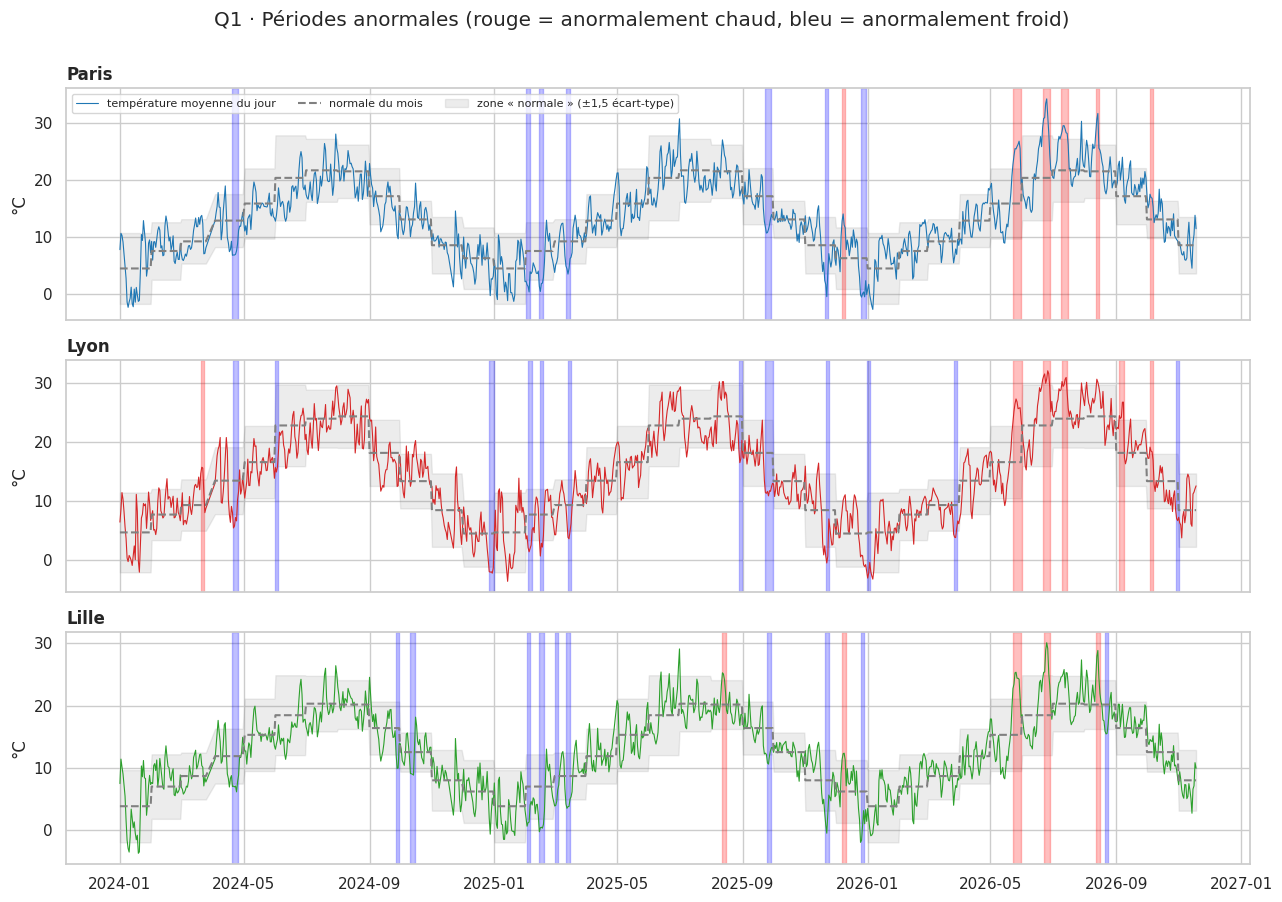

In [16]:
fig, axes = plt.subplots(len(CITIES), 1, figsize=(13, 9), sharex=True)
for ax, city in zip(axes, CITIES):
    g = daily[daily.city == city]
    ax.plot(g.date, g.t_mean, color=CITY_COLORS[city], lw=0.8, label="température moyenne du jour")
    ax.plot(g.date, g.norm, color="grey", lw=1.5, ls="--", label="normale du mois")
    ax.fill_between(g.date, g.norm - 1.5 * g.sd, g.norm + 1.5 * g.sd, color="grey", alpha=0.15,
                    label="zone « normale » (±1,5 écart-type)")
    for _, e in anomalies[anomalies.ville == city].iterrows():
        ax.axvspan(pd.Timestamp(e.debut), pd.Timestamp(e.fin) + pd.Timedelta(days=1),
                   color="red" if e.type == "chaud" else "blue", alpha=0.25)
    ax.set_title(city.capitalize(), loc="left", fontweight="bold")
    ax.set_ylabel("°C")
axes[0].legend(loc="upper left", fontsize=8, ncol=3)
fig.suptitle("Q1 · Périodes anormales (rouge = anormalement chaud, bleu = anormalement froid)", y=1.0)
fig.tight_layout(); save(fig, "q1_periodes_anormales"); plt.show()

In [17]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

features = ["t_mean", "t_max", "t_min", "wind_max", "precip", "pressure"]
X = daily[features].fillna(daily[features].median())
X = StandardScaler().fit_transform(X)
model = IsolationForest(n_estimators=300, contamination=0.02, random_state=42)
daily["iforest_anomalie"] = model.fit_predict(X) == -1
daily["iforest_score"] = -model.score_samples(X)          # plus c'est grand, plus c'est inhabituel

top_iforest = (daily[daily.iforest_anomalie]
               .sort_values("iforest_score", ascending=False)
               [["city", "date", "t_mean", "t_max", "t_min", "wind_max", "precip", "pressure", "source"]]
               .round(1))
print(f"IsolationForest : {daily.iforest_anomalie.sum()} jours inhabituels sur {len(daily)}")
top_iforest.head(15)

IsolationForest : 63 jours inhabituels sur 3108


,city,date,t_mean,t_max,t_min,wind_max,precip,pressure,source
722,lille,2026-01-09,4.1,7.7,1.8,12.4,24.1,986.1,openmeteo
1,lille,2024-01-02,11.4,12.6,9.0,15.2,18.4,991.7,noaa
2343,paris,2024-10-09,13.9,16.2,12.0,6.7,68.8,988.9,noaa
2088,paris,2024-01-17,1.2,5.4,-0.8,4.3,15.4,990.5,noaa
1034,lille,2026-11-17,10.8,14.1,5.7,9.7,23.7,985.8,openmeteo
644,lille,2025-10-23,11.5,15.1,8.0,12.1,13.2,984.3,openmeteo
1009,lille,2026-10-23,10.9,12.6,7.9,13.6,20.5,998.7,openmeteo
1076,lyon,2024-02-10,8.3,10.0,5.9,7.7,21.0,988.5,noaa
204,lille,2024-08-01,23.0,27.6,19.9,4.1,35.1,1012.0,noaa
3024,paris,2026-08-27,21.7,26.2,18.4,2.8,26.1,1009.2,openmeteo


**Lecture des résultats (Q1)** : *à compléter après exécution.* Exemples de points à relever :
combien de périodes chaudes ou froides, leurs dates (par exemple une vague de chaleur l'été),
leur durée et leur écart à la normale, et si IsolationForest retrouve les mêmes jours
(chaleur, tempête, fortes pluies).

---
## Question 2 · Existe-t-il une corrélation entre conditions météo et visibilité ?

On utilise les **mesures des stations NOAA** (table `clean`, toute la France), car la visibilité
y est mesurée par un instrument. (Open-Meteo ne fournit pas la visibilité sur la période ancienne.)

* **Corrélation de Spearman** : un nombre entre −1 et +1. Proche de −1 : quand l'un augmente,
  l'autre diminue ; proche de 0 : pas de lien. Spearman est adaptée ici car la visibilité est
  plafonnée par les instruments (souvent 10 km), ce qui fausserait une corrélation classique.
* **Courbes par tranche** : visibilité moyenne et part des heures de brouillard
  (visibilité < 1 km) selon l'humidité, la pluie et le vent. Calculées par Spark sur **toutes** les mesures.

Échantillon : 159,295 mesures


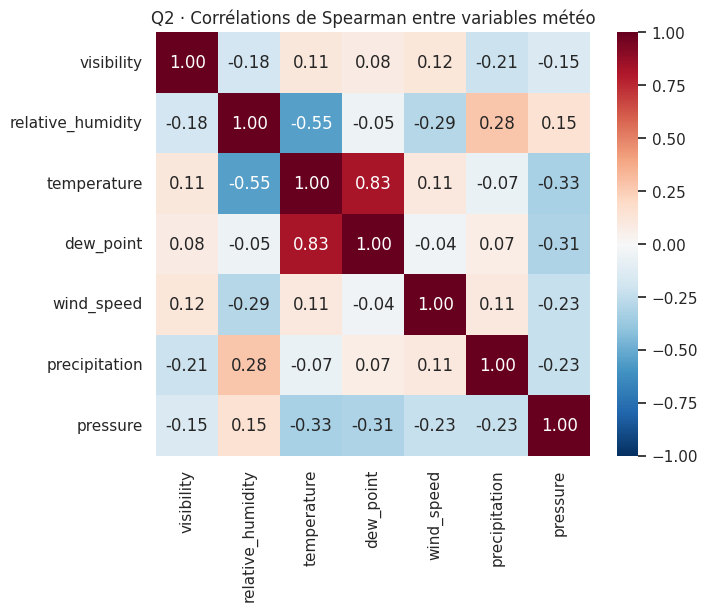

precipitation       -0.213588
relative_humidity   -0.183812
pressure            -0.145881
dew_point            0.081122
temperature          0.112310
wind_speed           0.123041
Name: visibility, dtype: float64

In [18]:
vis_vars = ["visibility", "relative_humidity", "temperature", "dew_point",
            "wind_speed", "precipitation", "pressure"]
sample = (clean.select(vis_vars).dropna(subset=["visibility", "relative_humidity"])
               .sample(fraction=0.05, seed=42).toPandas())
corr = sample.corr(method="spearman")
print(f"Échantillon : {len(sample):,} mesures")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Q2 · Corrélations de Spearman entre variables météo")
save(fig, "q2_correlations"); plt.show()
corr["visibility"].drop("visibility").sort_values()

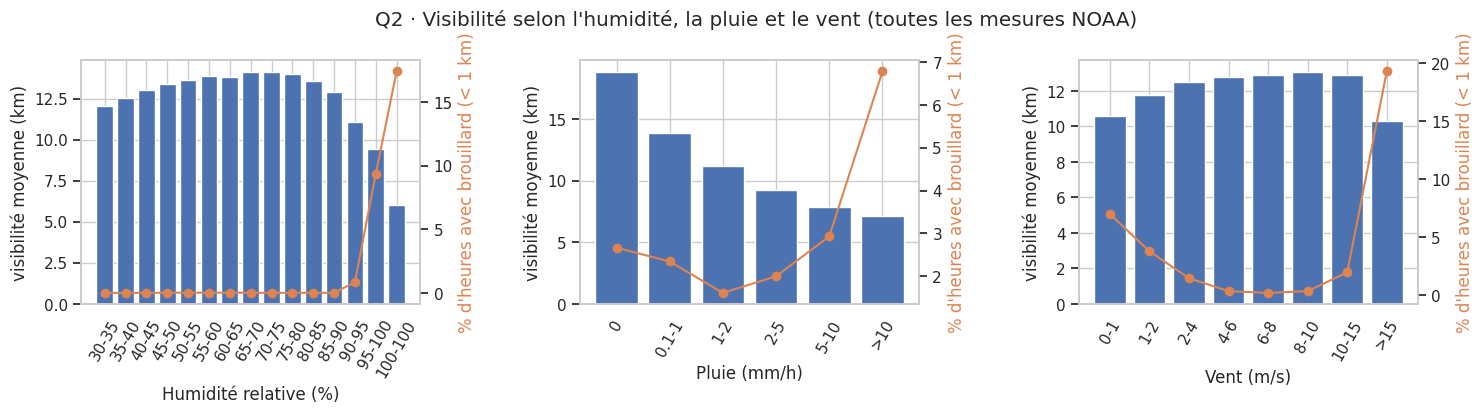

,visibilite_moy,part_brouillard,n
tranche,,,
30-35,12054.542,0.000,34815
35-40,12561.153,0.000,57752
40-45,13043.521,0.000,84269
45-50,13380.053,0.000,112535
50-55,13644.444,0.000,138487
55-60,13882.010,0.000,158966
60-65,13809.663,0.000,199515
65-70,14114.039,0.000,207511
70-75,14101.675,0.000,229305


In [19]:
def by_bins(col, edges, labels):
    bucket = F.when(F.col(col).isNull(), None)
    for lo, hi, lab in zip(edges[:-1], edges[1:], labels):
        bucket = bucket.when((F.col(col) >= lo) & (F.col(col) < hi), lab)
    return (clean.filter(F.col("visibility").isNotNull())
                 .withColumn("tranche", bucket).filter(F.col("tranche").isNotNull())
                 .groupBy("tranche")
                 .agg(F.avg("visibility").alias("visibilite_moy"),
                      F.avg((F.col("visibility") < 1000).cast("int")).alias("part_brouillard"),
                      F.count("*").alias("n"))
                 .toPandas().set_index("tranche").reindex(labels))

rh_edges = list(range(30, 101, 5)) + [101]
rh = by_bins("relative_humidity", rh_edges, [f"{a}-{b if b <= 100 else 100}" for a, b in zip(rh_edges[:-1], rh_edges[1:])])
pr = by_bins("precipitation", [0, 0.1, 1, 2, 5, 10, 300], ["0", "0.1-1", "1-2", "2-5", "5-10", ">10"])
wd = by_bins("wind_speed", [0, 1, 2, 4, 6, 8, 10, 15, 80], ["0-1", "1-2", "2-4", "4-6", "6-8", "8-10", "10-15", ">15"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (df, title) in zip(axes, [(rh, "Humidité relative (%)"), (pr, "Pluie (mm/h)"), (wd, "Vent (m/s)")]):
    ax.bar(df.index, df.visibilite_moy / 1000, color="#4c72b0")
    ax.set_ylabel("visibilité moyenne (km)"); ax.set_xlabel(title); ax.tick_params(axis="x", rotation=60)
    ax2 = ax.twinx(); ax2.plot(df.index, 100 * df.part_brouillard, color="#dd8452", marker="o")
    ax2.set_ylabel("% d'heures avec brouillard (< 1 km)", color="#dd8452"); ax2.grid(False)
fig.suptitle("Q2 · Visibilité selon l'humidité, la pluie et le vent (toutes les mesures NOAA)")
fig.tight_layout(); save(fig, "q2_visibilite_par_tranche"); plt.show()
rh.round(3)

**Lecture des résultats (Q2)** : *à compléter après exécution.* Points attendus : l'humidité est-elle
la variable la plus liée à la visibilité (le brouillard se forme quand l'air est saturé, près de 100 %) ?
La pluie réduit-elle la visibilité ? Le vent l'améliore-t-il (il disperse la brume) ?

---
## Question 3 · Évolution saisonnière de la température (France et grandes villes)

* **France** : moyenne de toutes les stations NOAA françaises (d'abord par station et par mois,
  puis moyenne des stations, pour qu'une station très bavarde ne pèse pas plus qu'une autre).
  Période : 01/2024 → 08/2025.
* **Villes** : Paris, Lyon, Lille, de 01/2024 à aujourd'hui (NOAA puis Open-Meteo).

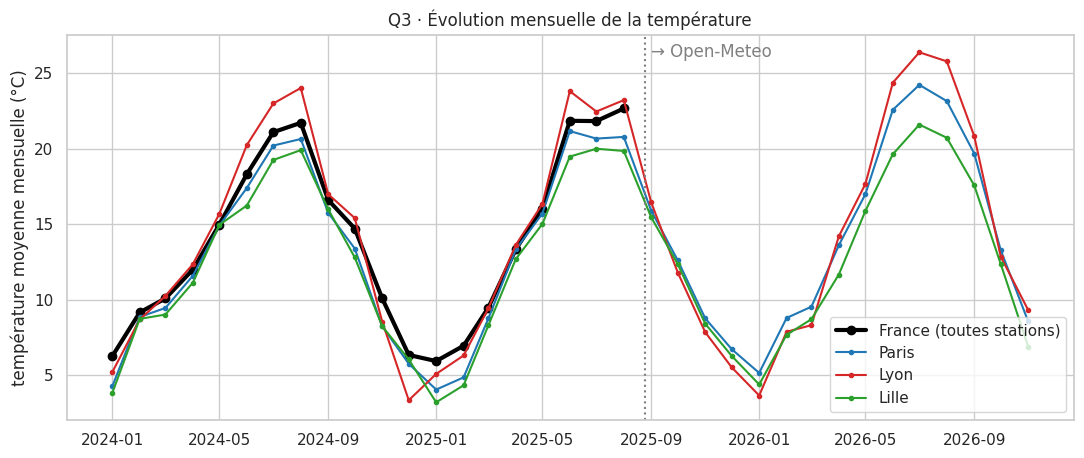

In [20]:
france_month = (clean
    .withColumn("mois", F.date_trunc("month", "timestamp"))
    .groupBy("station_id", "mois").agg(F.avg("temperature").alias("t"))
    .groupBy("mois").agg(F.avg("t").alias("temperature"), F.countDistinct("station_id").alias("stations"))
    .orderBy("mois").toPandas())
city_month = (curated
    .withColumn("mois", F.date_trunc("month", "timestamp"))
    .groupBy("city", "mois").agg(F.avg("temperature").alias("temperature"),
                                 F.min("temperature").alias("t_min"), F.max("temperature").alias("t_max"))
    .orderBy("city", "mois").toPandas())

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(france_month.mois, france_month.temperature, color="black", lw=3, marker="o", label="France (toutes stations)")
for city in CITIES:
    g = city_month[city_month.city == city]
    ax.plot(g.mois, g.temperature, color=CITY_COLORS[city], marker=".", label=city.capitalize())
ax.axvline(pd.Timestamp("2025-08-25"), color="grey", ls=":")
ax.text(pd.Timestamp("2025-09-01"), ax.get_ylim()[1] - 1.5, "→ Open-Meteo", color="grey")
ax.set_ylabel("température moyenne mensuelle (°C)"); ax.legend()
ax.set_title("Q3 · Évolution mensuelle de la température")
save(fig, "q3_evolution_mensuelle"); plt.show()

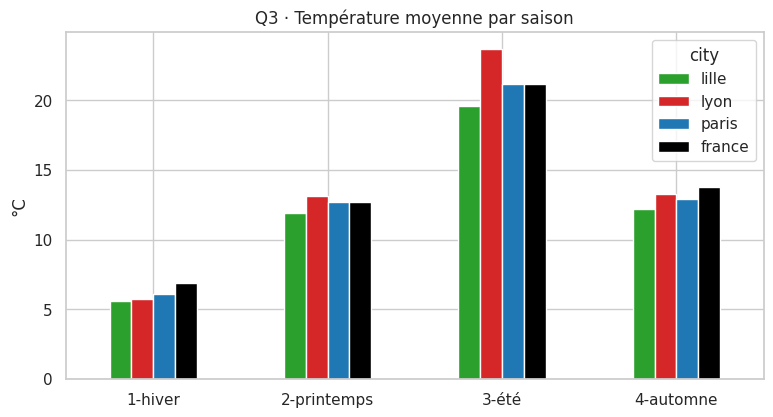

city,lille,lyon,paris,france
saison,,,,
1-hiver,5.6,5.7,6.1,6.9
2-printemps,11.9,13.1,12.7,12.7
3-été,19.6,23.7,21.2,21.2
4-automne,12.2,13.3,12.9,13.8
écart été - hiver,14.0,18.0,15.1,14.3


In [21]:
SEASONS = {12: "1-hiver", 1: "1-hiver", 2: "1-hiver", 3: "2-printemps", 4: "2-printemps", 5: "2-printemps",
           6: "3-été", 7: "3-été", 8: "3-été", 9: "4-automne", 10: "4-automne", 11: "4-automne"}
city_month["saison"] = city_month.mois.dt.month.map(SEASONS)
france_month["saison"] = france_month.mois.dt.month.map(SEASONS)
seasons = city_month.groupby(["saison", "city"]).temperature.mean().unstack()
seasons["france"] = france_month.groupby("saison").temperature.mean()
seasons = seasons.round(1)
seasons.loc["écart été - hiver"] = (seasons.loc["3-été"] - seasons.loc["1-hiver"]).round(1)
seasons.to_csv(f"{RES_DIR}/meteo_saisons.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
seasons.drop("écart été - hiver").plot.bar(ax=ax, color=[CITY_COLORS.get(c, "black") for c in seasons.columns])
ax.set_ylabel("°C"); ax.set_xlabel(""); ax.set_title("Q3 · Température moyenne par saison"); ax.tick_params(axis="x", rotation=0)
save(fig, "q3_saisons"); plt.show()
seasons

**Lecture des résultats (Q3)** : *à compléter après exécution.* Points attendus : le cycle des saisons
(minimum en janvier-février, maximum en juillet-août), l'écart été-hiver de chaque ville
(Lyon, plus continentale, a souvent des étés plus chauds ; Lille, plus au nord et influencée par la mer,
a des étés plus frais), et la comparaison avec la moyenne France.

---
## Question 4 · Quels sont les jours présentant des conditions météorologiques extrêmes ?

Un jour est **extrême** s'il dépasse au moins un de ces seuils (inspirés des vigilances Météo-France) :

| Type | Seuil |
|---|---|
| 🔥 forte chaleur | température maximale ≥ 33 °C |
| 🥶 froid intense | température minimale ≤ −5 °C |
| 🌧️ fortes pluies | cumul de pluie ≥ 20 mm dans la journée |
| 💨 vent fort | vent moyen horaire maximal ≥ 12 m/s (≈ 43 km/h, rafales bien plus fortes) |

En complément, on liste les jours les plus « hors normes » de chaque type (centile 99 %).

In [22]:
THRESHOLDS = {
    "forte chaleur": ("t_max", ">=", 33),
    "froid intense": ("t_min", "<=", -5),
    "fortes pluies": ("precip", ">=", 20),
    "vent fort":     ("wind_max", ">=", 12),
}
rows = []
for kind, (col, op, value) in THRESHOLDS.items():
    hit = daily[daily[col] >= value] if op == ">=" else daily[daily[col] <= value]
    for _, r in hit.iterrows():
        rows.append({"ville": r.city, "date": r.date.date(), "type": kind, "valeur": round(r[col], 1),
                     "t_max": round(r.t_max, 1), "t_min": round(r.t_min, 1), "pluie_mm": round(r.precip, 1),
                     "vent_max": round(r.wind_max, 1), "source": r.source})
extremes = pd.DataFrame(rows).sort_values(["date", "ville"]).reset_index(drop=True)
extremes.to_csv(f"{RES_DIR}/meteo_jours_extremes.csv", index=False)

print("Nombre de jours extrêmes par ville et par type :")
display(extremes.pivot_table(index="ville", columns="type", values="date", aggfunc="count", fill_value=0))

Nombre de jours extrêmes par ville et par type :


type,forte chaleur,fortes pluies,froid intense,vent fort
ville,,,,
lille,9,5,6,19
lyon,76,23,5,13
paris,32,9,2,0


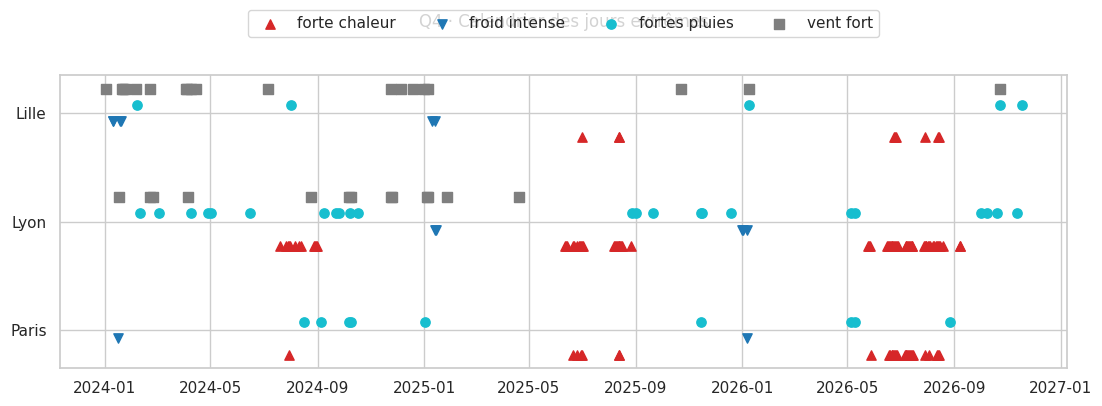

,type,city,date,t_max,t_min,precip,wind_max,source
2960,plus chaud (t_max),paris,2026-06-24,40.3,25.2,0.1,3.5,openmeteo
2961,plus chaud (t_max),paris,2026-06-25,39.8,26.9,0.0,4.5,openmeteo
3011,plus chaud (t_max),paris,2026-08-14,39.1,23.7,0.0,5.4,openmeteo
18,plus froid (t_min),lille,2024-01-19,3.0,-7.6,0.5,4.4,noaa
1750,plus froid (t_min),lyon,2026-01-01,2.7,-7.3,0.0,1.4,openmeteo
1751,plus froid (t_min),lyon,2026-01-02,2.5,-6.7,0.0,1.5,openmeteo
1146,plus pluvieux,lyon,2024-04-28,14.1,9.9,79.0,4.6,noaa
1306,plus pluvieux,lyon,2024-10-08,18.5,13.0,76.2,5.6,noaa
2343,plus pluvieux,paris,2024-10-09,16.2,12.0,68.8,6.7,noaa
1350,plus venteux,lyon,2024-11-25,18.4,11.0,8.0,18.0,noaa


In [23]:
fig, ax = plt.subplots(figsize=(13, 3.8))
markers = {"forte chaleur": ("^", "#d62728"), "froid intense": ("v", "#1f77b4"),
           "fortes pluies": ("o", "#17becf"), "vent fort": ("s", "#7f7f7f")}
ypos = {c: i for i, c in enumerate(CITIES)}
for kind, (m, color) in markers.items():
    e = extremes[extremes.type == kind]
    ax.scatter(pd.to_datetime(e.date), e.ville.map(ypos) + 0.15 * (list(markers).index(kind) - 1.5),
               marker=m, color=color, s=45, label=kind)
ax.set_yticks(list(ypos.values()), [c.capitalize() for c in ypos])
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.25))
ax.set_title("Q4 · Calendrier des jours extrêmes", pad=35)
save(fig, "q4_jours_extremes"); plt.show()

# Les jours les plus extrêmes de chaque type
top = pd.concat([
    daily.nlargest(3, "t_max").assign(type="plus chaud (t_max)"),
    daily.nsmallest(3, "t_min").assign(type="plus froid (t_min)"),
    daily.nlargest(3, "precip").assign(type="plus pluvieux"),
    daily.nlargest(3, "wind_max").assign(type="plus venteux"),
])[["type", "city", "date", "t_max", "t_min", "precip", "wind_max", "source"]].round(1)
top

**Lecture des résultats (Q4)** : *à compléter après exécution.* Points attendus : les vagues de chaleur
(dates et villes), les jours de gel, les épisodes de fortes pluies ou de tempête, et les liens avec la Q1
(les jours extrêmes tombent-ils dans les périodes anormales ?).

---
### Limites générales
* Période courte (~3 ans) : les « normales » et les seuils sont calculés sur peu d'années.
* Après le 24/08/2025, les données viennent d'**Open-Meteo** (modèle météo, grille ~10 km) et non de stations :
  les valeurs sont plus lisses (moins de pics) et la visibilité n'est pas disponible.
* Précipitations NOAA : cumul ramené à l'heure à partir de durées de 1 h ou 3 h (approximation).
  Certaines heures n'ont pas de mesure de pluie (~15 heures renseignées sur 24 en moyenne) :
  les cumuls journaliers et annuels sont donc **sous-estimés** ; les jours de fortes pluies restent bien repérés
  (ex. tempête Kirk à Paris le 09/10/2024).

In [24]:
spark.stop()